# Thesis Fig. 7 — joint optimum of kernel and sampling across budgets

Reproduction of Tepper (2026), Fig. 7 (thesis PDF p. 93; printed p. 86), panel by panel.

> Joint kernel-and-sampling optima for a Gaussian target spectrum (σ = 16) at four budgets B0. Rows: optimal kernel;
> target and readout; target and readout PSD with the active boundary; reconstruction error E*(B0) over a budget sweep.

**Panels:** A kernels · B readout vs target · C PSDs · D error against budget.

**Acceptance (spec 6A.6):** T* = 2M* at each budget; error decreasing in B0.

**Parameters [D11]:** `configs/thesis/fig7.yaml`. λ is calibrated (5×10⁻⁴) so that the closed form (eq. 8.9)
reproduces the printed M* values; with one parameter it matches all four within ±1, which is the independent content.
The joint optimum uses κ = λ/2 (eq. 8.9). The readout is the per-mode ridge filter g*_m ŷ_m on |m| ≤ M* (eq. 4.5a)
with T* = 2M* observations; errors are the eq. 6.21 terms at T_obs = T*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seqnet.thesis as th
from seqnet.thesis.figures import load_config, save_data, load_data, save_figure, record_checks, style

style()
FIG = "fig7"
cfg = load_config(FIG)
N, lam = cfg["N"], cfg["decay"]
m = np.arange(N // 2 + 1)
S = np.exp(-m**2 / (2 * cfg["psd_sigma"] ** 2))
B = np.array(cfg["budgets"])
J = [th.joint_optimum(S, lam, b, None, N, method="thesis") for b in B]
[(j.M_star, j.T_star, round(j.budget_residual, 6)) for j in J]

[(6, 12, np.float64(0.0)),
 (32, 64, np.float64(0.0)),
 (63, 126, np.float64(0.0)),
 (89, 178, np.float64(0.0))]

## Panel A — optimal kernels (inverse DFT of a*, positive signs)

In [2]:
Kv = np.stack([th.Kernel.from_alloc(j.a, N).values for j in J])
save_data(FIG, "A_kernels", params={"budgets": B, "decay": lam}, r=th.Ring(N).centred_positions, K=Kv,
          M=np.array([j.M_star for j in J]), T=np.array([j.T_star for j in J]),
          figure_M=np.array(cfg["figure_M"]), figure_T=np.array(cfg["figure_T"]))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig7/A_kernels.npz')

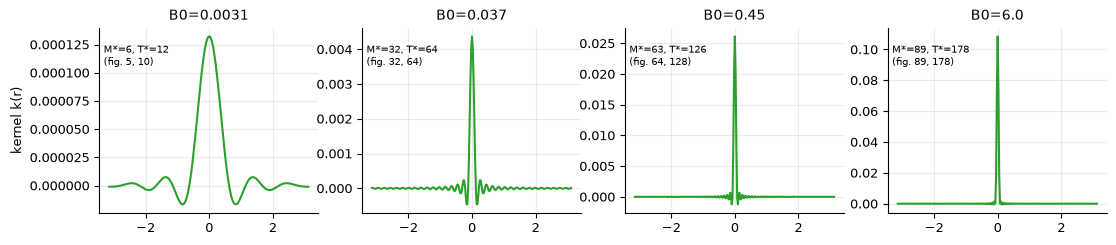

In [3]:
d = load_data(FIG, "A_kernels"); o = np.argsort(d["r"])
fig, axs = plt.subplots(1, 4, figsize=(13, 2.4))
for ax, kv, b, M, T, fm, ft in zip(axs, d["K"], B, d["M"], d["T"], d["figure_M"], d["figure_T"]):
    ax.plot(d["r"][o], kv[o], color="tab:green"); ax.set_title(f"B0={b}")
    ax.text(0.02, 0.8, f"M*={M}, T*={T}\n(fig. {fm}, {ft})", transform=ax.transAxes, fontsize=7)
axs[0].set_ylabel("kernel k(r)")
save_figure(FIG, "A_kernels", fig); plt.show()

## Panel B — target and readout (one random-phase draw; per-mode ridge filter g*_m)

In [4]:
rng = np.random.default_rng(cfg["seed"])
tc = th.TargetClass(psd=S)
coeffs = tc.coeffs(rng)
c = np.linspace(-np.pi, np.pi, 1024, endpoint=False)
y = tc.evaluate(coeffs, N, c)
YH = []
for j in J:
    g = np.where(m <= j.M_star, th.spectral_filter(j.a, lam), 0.0)
    YH.append(tc.evaluate(coeffs * g, N, c))
save_data(FIG, "B_readout", c=c, y=y, YH=np.stack(YH))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig7/B_readout.npz')

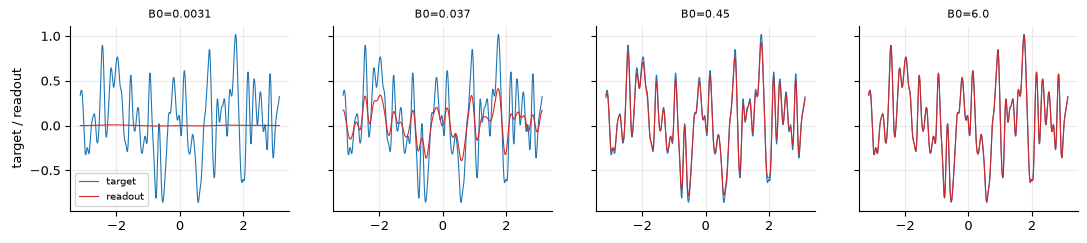

In [5]:
d = load_data(FIG, "B_readout")
fig, axs = plt.subplots(1, 4, figsize=(13, 2.4), sharey=True)
for ax, yh, b in zip(axs, d["YH"], B):
    ax.plot(d["c"], d["y"], color="tab:blue", lw=0.8, label="target"); ax.plot(d["c"], yh, color="tab:red", lw=0.8, label="readout")
    ax.set_title(f"B0={b}", fontsize=8)
axs[0].legend(fontsize=7); axs[0].set_ylabel("target / readout")
save_figure(FIG, "B_readout", fig); plt.show()

## Panel C — target PSD and readout PSD g*²S, active boundary M*

In [6]:
P = np.stack([np.where(m <= j.M_star, th.spectral_filter(j.a, lam) ** 2, 0.0) * S for j in J])
save_data(FIG, "C_psd", m=m, S=S, P=P, M=np.array([j.M_star for j in J]))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig7/C_psd.npz')

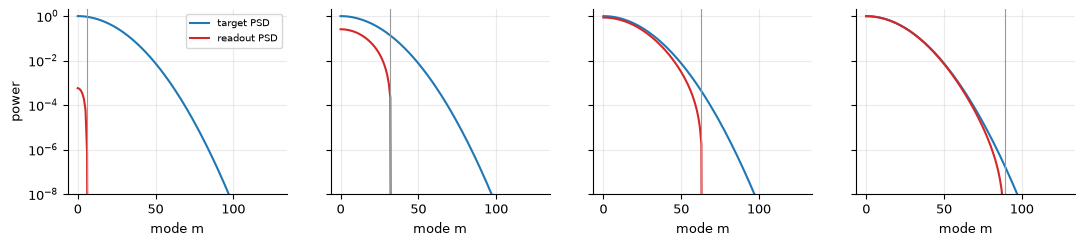

In [7]:
d = load_data(FIG, "C_psd")
fig, axs = plt.subplots(1, 4, figsize=(13, 2.4), sharey=True)
for ax, p, M in zip(axs, d["P"], d["M"]):
    ax.semilogy(d["m"], d["S"], color="tab:blue", label="target PSD"); ax.semilogy(d["m"], p + 1e-30, color="tab:red", label="readout PSD")
    ax.axvline(M, color="0.6", lw=0.8); ax.set_ylim(1e-8, 2); ax.set_xlabel("mode m")
axs[0].legend(fontsize=7); axs[0].set_ylabel("power")
save_figure(FIG, "C_psd", fig); plt.show()

## Panel D — optimal error E*(B0) over the budget sweep (eq. 8.2 at the eq. 8.9 optimum)

In [8]:
sw = cfg["sweep"]; Bs = np.geomspace(sw["lo"], sw["hi"], sw["n"])
E, Ms, Ts = [], [], []
for b in Bs:
    j = th.joint_optimum(S, lam, b, None, N, method="thesis")
    E.append(th.error_terms(j.a, S, lam, max(j.T_star, 1), N).total); Ms.append(j.M_star); Ts.append(j.T_star)
E_pts = [th.error_terms(j.a, S, lam, j.T_star, N).total for j in J]
save_data(FIG, "D_error_sweep", B=Bs, E=np.array(E), M=np.array(Ms), T=np.array(Ts), B_pts=B, E_pts=np.array(E_pts))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig7/D_error_sweep.npz')

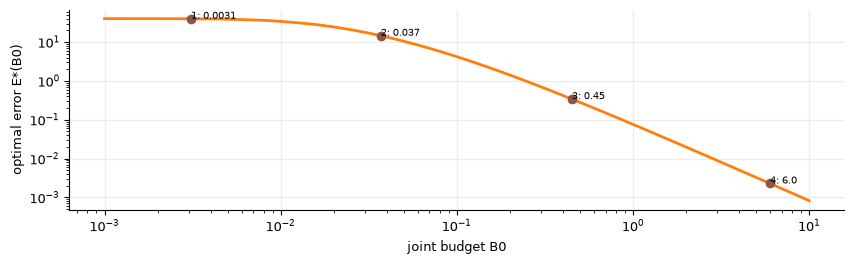

In [9]:
d = load_data(FIG, "D_error_sweep")
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.loglog(d["B"], d["E"], color="tab:orange", lw=2); ax.loglog(d["B_pts"], d["E_pts"], "o", color="tab:brown")
for i, (b, e) in enumerate(zip(d["B_pts"], d["E_pts"])): ax.annotate(f"{i+1}: {b}", (b, e), fontsize=7)
ax.set_xlabel("joint budget B0"); ax.set_ylabel("optimal error E*(B0)")
save_figure(FIG, "D_error_sweep", fig); plt.show()

## Acceptance

In [10]:
a = load_data(FIG, "A_kernels"); s = load_data(FIG, "D_error_sweep")
dE = np.diff(s["E"])
checks = [
    {"item": "T* = 2M* at each budget", "criterion": "exact", "value": {"M": a["M"], "T": a["T"]}, "passed": bool(np.all(a["T"] == 2 * a["M"]))},
    {"item": "error decreasing in B0", "criterion": "non-increasing over the sweep", "value": float(dE.max()), "passed": bool(np.all(dE <= 1e-12))},
    {"item": "M* vs printed values (lambda calibrated)", "criterion": "|M* - fig| <= 1",
     "value": {"reproduced": a["M"], "figure": a["figure_M"]}, "passed": bool(np.all(np.abs(a["M"] - a["figure_M"]) <= 1))},
]
record_checks(FIG, checks)
for c in checks: print(c)

{'item': 'T* = 2M* at each budget', 'criterion': 'exact', 'value': {'M': array([ 6, 32, 63, 89]), 'T': array([ 12,  64, 126, 178])}, 'passed': True}
{'item': 'error decreasing in B0', 'criterion': 'non-increasing over the sweep', 'value': 0.0, 'passed': True}
{'item': 'M* vs printed values (lambda calibrated)', 'criterion': '|M* - fig| <= 1', 'value': {'reproduced': array([ 6, 32, 63, 89]), 'figure': array([ 5, 32, 64, 89])}, 'passed': True}
